# 05 — Phase 2, Experiments 2–4: braking, turning, and combine execution cost (real data)

**Guardrails.**
- Capacity, execution, measurement uncertainty and performance are kept **separate**. No performance or career outcomes are used.
- `player_play` supplies only *context*: run vs pass play, route type.
- A theoretical friction limit is **not** assumed to be observable. Everything measured here is a *demonstrated envelope*: what players were seen to do, which is a lower bound on capacity.

Pipelines:
- `scripts/run_real_movement.py`: REG + POST, post-snap frames only, documented exclusions.
- `scripts/run_real_combine_execution.py`.

**Estimators compared.**

| Name | Longitudinal (braking) | Lateral |
|---|---|---|
| pos5 / pos7 / pos9 | tangential a_t from SG derivatives of x, y (window 5/7/9 frames) | a_n = \|v × a\|/\|v\| from the same SG fit |
| speed_sg7 / speed_diff | SG (7) or central-difference derivative of the provided speed `s` | a_n from the provided heading: s·\|d dir/dt\| |
| noise0.01 / noise0.02 | pos7 after adding N(0, σ²) position noise (σ = 0.01 / 0.02 yd) | same |
| 5hz | pos with SG window 5 on every 2nd frame (5 Hz) | same |

Braking is reported as positive deceleration (−a_t). **The provided `a` is an unsigned total-acceleration magnitude, so it cannot separate braking from turning.**

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")
import numpy as np, polars as pl, matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from nfl_bdb.visualization import style
style.apply(); pl.Config.set_tbl_rows(80); pl.Config.set_tbl_width_chars(220); pl.Config.set_tbl_hide_dataframe_shape(True)
FIG = ROOT / "reports" / "figures"
def save(fig, name): fig.savefig(FIG / f"real_mov_{name}.png", bbox_inches="tight", dpi=150)
mrun = (ROOT/"experiments/real_movement/LATEST").read_text().strip(); MD = ROOT/f"experiments/real_movement/{mrun}"
erun = (ROOT/"experiments/real_execution/LATEST").read_text().strip(); ED = ROOT/f"experiments/real_execution/{erun}"
FA = pl.read_parquet(MD/"frame_agreement.parquet"); SB = pl.read_parquet(MD/"speed_bins.parquet"); DEC = pl.read_parquet(MD/"decomposition.parquet")
PM = pl.read_parquet(MD/"player_measures.parquet"); EXC = pl.read_parquet(MD/"exposure_curve.parquet"); CM = pl.read_parquet(MD/"combine_movement.parquet")
A = pl.read_parquet(ED/"attempts.parquet")
print("movement run", mrun, "| exclusions", json.load(open(MD/"exclusions.json"))["2025"])
print("execution run", erun)
POS = style.POSITION_ORDER; PCOL = style.POSITION_COLOR
rng = np.random.default_rng(0)
def boot_r(x, y, f=lambda a,b: spearmanr(a,b).statistic, B=2000):
    x, y = np.asarray(x, float), np.asarray(y, float); ok = np.isfinite(x) & np.isfinite(y); x, y = x[ok], y[ok]
    if len(x) < 8: return (np.nan, np.nan, np.nan, len(x))
    est = f(x, y); bs = [f(x[i], y[i]) for i in (rng.integers(0, len(x), len(x)) for _ in range(B))]
    lo, hi = np.nanpercentile(bs, [2.5, 97.5]); return (est, lo, hi, len(x))
base = PM.filter((pl.col("scope")=="all_") & (pl.col("context")=="all_plays"))

movement run 20261120T231614Z | exclusions {'sequences_loaded': 132938, 'removed_faulty_game': 7, 'removed_speed_spike': 1, 'sequences_kept': 132930}
execution run 20261120T231805Z


# Part A — Experiment 2: braking (longitudinal deceleration)
## A1 · Frame-level agreement between estimators and physically implausible values

In [2]:
fa = FA.filter(pl.col("kind")=="a_t").group_by("variant").agg(pl.col("n").sum(), pl.col("corr_with_pos7").mean().round(3),
      (pl.col("frac_implausible")*pl.col("n")).sum().truediv(pl.col("n").sum()).mul(100).round(4).alias("pct_frames_|a_t|>12"),
      pl.col("p99_brake").mean().round(2).alias("mean_p99_braking"), pl.col("p999_brake").mean().round(2).alias("mean_p999_braking")).sort("variant")
fa

variant,n,corr_with_pos7,pct_frames_|a_t|>12,mean_p99_braking,mean_p999_braking
str,i64,f64,f64,f64,f64
"""at_5hz""",7268732,0.994,0.0021,4.79,6.43
"""at_noise0.01""",15722692,0.994,0.0095,4.91,6.75
"""at_noise0.02""",15722692,0.977,0.0097,4.98,6.85
"""at_pos5""",15722692,0.982,0.023,5.04,7.21
"""at_pos7""",15722692,1.0,0.0095,4.88,6.72
"""at_pos9""",15458787,0.996,0.002,4.76,6.43
"""at_sdiff""",15722689,0.974,0.0011,4.98,6.87
"""at_ssg7""",15722692,0.976,0.0002,4.57,6.14


- Frame-level correlations with the pos7 reference show how much each estimator *disagrees* frame by frame. Downsampling to 5 Hz and injected noise are the least similar.
- The 12 yd/s² (≈ 11 m/s²) implausibility threshold is a stated assumption, not a validated limit.

## A2 · Braking vs speed (pooled by position)

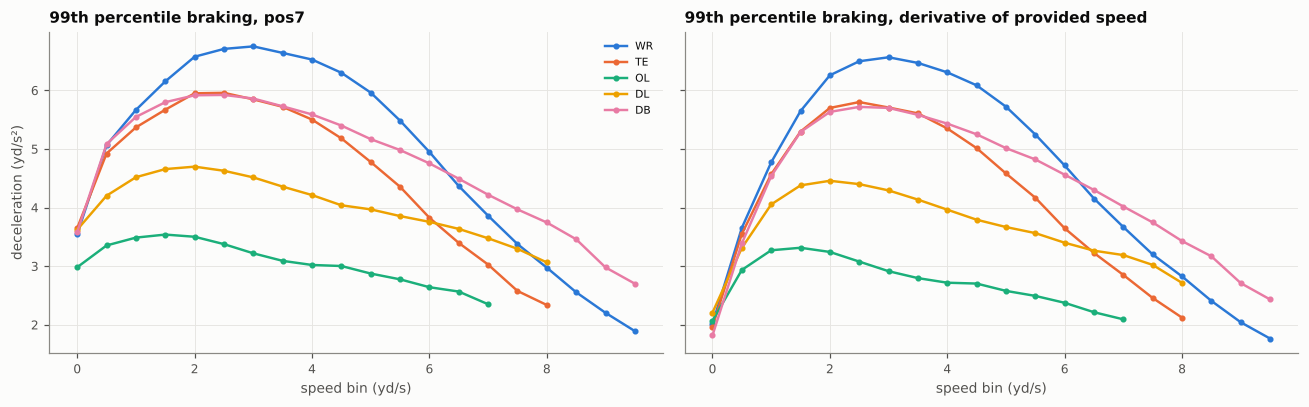

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, lab in [(axes[0], "brake_at_pos7_q990", "99th percentile braking, pos7"), (axes[1], "brake_at_ssg7_q990", "99th percentile braking, derivative of provided speed")]:
    for p in POS:
        q = SB.filter((pl.col("pos")==p) & (pl.col("n")>2000)).sort("v_bin")
        ax.plot(q["v_bin"], q[col], marker="o", ms=3, color=PCOL[p], label=p)
    ax.set_xlabel("speed bin (yd/s)"); ax.set_title(lab, loc="left", fontsize=10)
axes[0].set_ylabel("deceleration (yd/s²)"); axes[0].legend(fontsize=7)
fig.tight_layout(); save(fig, "braking_vs_speed")

## A3 · Separating braking from turning

In [4]:
DEC.with_columns(pl.col(c).round(3) for c in ("provided_a_median","braking_median","an_median","share_a2_from_turning","corr_provided_a_vs_vec7")).sort("pos","kclass")

pos,kclass,n,provided_a_median,braking_median,an_median,share_a2_from_turning,corr_provided_a_vs_vec7
str,str,u32,f32,f32,f32,f32,f32
"""DB""","""moderate""",107855,3.5,3.889,1.437,0.109,0.645
"""DB""","""sharp""",60065,4.1,3.991,2.963,0.334,0.635
"""DB""","""straight""",91555,3.21,3.839,0.408,0.01,0.666
"""DL""","""moderate""",39437,3.19,3.66,1.11,0.078,0.539
"""DL""","""sharp""",24103,3.46,3.688,2.404,0.281,0.597
"""DL""","""straight""",27375,3.17,3.66,0.302,0.006,0.57
"""OL""","""moderate""",17998,2.8,3.437,0.822,0.051,0.381
"""OL""","""sharp""",10577,2.87,3.43,1.88,0.22,0.357
"""OL""","""straight""",10249,2.81,3.445,0.204,0.003,0.243


Braking frames (a_t < −3 yd/s², speed ≥ 2 yd/s) are classed by curvature: straight κ < 0.05, moderate, sharp κ ≥ 0.2 yd⁻¹.
- In sharp turns, a large share of the squared total acceleration comes from the **normal** (turning) component. The provided `a` therefore overstates braking there.
- Speed lost *while turning* is still longitudinal deceleration, because speed changes only through a_t. What turning adds is a_n.
- So "braking during turns" and "braking in straight lines" are reported separately (D99_straight, D99_turn).

## A4 · Player-level braking measures: sensitivity to the estimator

In [5]:
W = base.pivot(on="variant", index="nfl_id", values="D99")
vs = ["pos5","pos9","speed_sg7","speed_diff","noise0.01","noise0.02","5hz"]
q = W.join(base.filter(pl.col("variant")=="pos7").select("nfl_id","n_plays","pos"), on="nfl_id").filter(pl.col("n_plays")>=100)
rows=[]
for v in vs:
    r,lo,hi,n = boot_r(q["pos7"], q[v])
    rows.append(dict(variant=v, n=n, spearman_with_pos7=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]",
                     median_ratio_to_pos7=round(float(np.nanmedian(q[v]/q["pos7"])),3)))
pl.DataFrame(rows)

variant,n,spearman_with_pos7,CI95,median_ratio_to_pos7
str,i64,f64,str,f64
"""pos5""",307,0.997,"""[1.00, 1.00]""",1.029
"""pos9""",307,0.998,"""[1.00, 1.00]""",0.975
"""speed_sg7""",307,0.995,"""[0.99, 1.00]""",0.958
"""speed_diff""",307,0.995,"""[0.99, 1.00]""",1.015
"""noise0.01""",307,0.999,"""[1.00, 1.00]""",1.006
"""noise0.02""",307,0.998,"""[1.00, 1.00]""",1.02
"""5hz""",307,0.996,"""[0.99, 1.00]""",0.971


In [6]:
plaus = base.filter((pl.col("variant")=="pos7") & (pl.col("n_plays")>=100))
print("players with ≥100 plays:", plaus.height)
print("Dmax > 12 yd/s² (implausible single-frame max):", (plaus["Dmax"]>12).sum(), f"({100*(plaus['Dmax']>12).mean():.1f}%)")
print("D99 > 12 yd/s²:", (plaus["D99"]>12).sum(), "| D99 range:", plaus["D99"].min().__round__(2), "–", plaus["D99"].max().__round__(2))
plaus.group_by("pos").agg(pl.len(), pl.col("D99").median().round(2), pl.col("D99_straight").median().round(2), pl.col("D99_turn").median().round(2), pl.col("Dmax").median().round(2)).sort("pos")

players with ≥100 plays: 307
Dmax > 12 yd/s² (implausible single-frame max): 135 (44.0%)
D99 > 12 yd/s²: 0 | D99 range: 2.92 – 6.51


pos,len,D99,D99_straight,D99_turn,Dmax
str,u32,f32,f32,f32,f32
"""DB""",74,5.47,5.33,5.81,15.3
"""DL""",78,4.26,4.14,4.35,7.89
"""OL""",70,3.32,3.24,3.37,6.4
"""TE""",22,5.24,5.0,5.67,14.78
"""WR""",63,5.94,5.47,6.79,18.66


## A5 · Reliability: split-half (game parity) and season-to-season

In [7]:
def split_half(measure, variant="pos7", context="all_plays", min_plays=100, by_pos=False):
    h = PM.filter((pl.col("variant")==variant) & (pl.col("context")==context) & pl.col("scope").is_in(["half_0","half_1"]))
    w = h.pivot(on="scope", index=["nfl_id","pos"], values=measure).join(
        PM.filter((pl.col("variant")==variant)&(pl.col("context")==context)&(pl.col("scope")=="all_")).select("nfl_id","n_plays"), on="nfl_id")
    w = w.filter(pl.col("n_plays")>=min_plays)
    groups = [("ALL", w)] + ([(p, w.filter(pl.col("pos")==p)) for p in POS] if by_pos else [])
    out=[]
    for g, d in groups:
        r,lo,hi,n = boot_r(d["half_0"], d["half_1"])
        out.append(dict(measure=measure, variant=variant, context=context, group=g, n=n, split_half_rho=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]", spearman_brown=round(2*r/(1+r),3)))
    return out
rows=[]
for m in ["D99","D99_straight","D99_turn","Dmax"]:
    for v in ["pos7","pos5","pos9","speed_sg7","5hz","noise0.02"]:
        rows += split_half(m, v)
REL_B = pl.DataFrame(rows); REL_B.pivot(on="variant", index="measure", values="spearman_brown")

measure,pos7,pos5,pos9,speed_sg7,5hz,noise0.02
str,f64,f64,f64,f64,f64,f64
"""D99""",0.972,0.971,0.973,0.971,0.973,0.972
"""D99_straight""",0.944,0.947,0.945,0.949,0.949,0.948
"""D99_turn""",0.968,0.97,0.968,0.969,0.963,0.963
"""Dmax""",0.811,0.766,0.845,0.921,0.863,0.817


In [8]:
def season_stability(measure, variant="pos7", min_plays=100):
    s = PM.filter((pl.col("variant")==variant)&(pl.col("context")=="all_plays")&pl.col("scope").str.starts_with("season_")&(pl.col("n_plays")>=min_plays))
    w = s.pivot(on="scope", index="nfl_id", values=measure)
    out=[]
    for a,b in [("season_2023","season_2024"),("season_2024","season_2025")]:
        if a in w.columns and b in w.columns:
            r,lo,hi,n=boot_r(w[a],w[b]); out.append(dict(measure=measure, seasons=f"{a[-4:]}→{b[-4:]}", n=n, rho=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]"))
    return out
pl.DataFrame(sum([season_stability(m) for m in ["D99","D99_straight","C99"]], []))

measure,seasons,n,rho,CI95
str,str,i64,f64,str
"""D99""","""2023→2024""",65,0.96,"""[0.92, 0.97]"""
"""D99""","""2024→2025""",139,0.94,"""[0.90, 0.96]"""
"""D99_straight""","""2023→2024""",65,0.902,"""[0.83, 0.94]"""
"""D99_straight""","""2024→2025""",139,0.889,"""[0.84, 0.92]"""
"""C99""","""2023→2024""",65,0.96,"""[0.92, 0.98]"""
"""C99""","""2024→2025""",139,0.954,"""[0.93, 0.97]"""


## A6 · Exposure: does the braking envelope keep growing with more plays? (censoring)

In [9]:
ex = EXC.with_columns(pl.when(pl.col("k")==-1).then(pl.col("n_total")).otherwise(pl.col("k")).alias("plays"))
full = ex.filter(pl.col("k")==-1).select("nfl_id", pl.col("D99").alias("D99_full"), pl.col("C99").alias("C99_full"))
rel = ex.filter(pl.col("k")>0).join(full, on="nfl_id").group_by("k").agg(pl.len().alias("n"),
    (pl.col("D99")/pl.col("D99_full")).median().round(3).alias("D99_ratio_to_full"), (pl.col("C99")/pl.col("C99_full")).median().round(3).alias("C99_ratio_to_full"),
    (pl.col("Dmax")).median().round(2).alias("Dmax_median")).sort("k")
print("players with ≥300 plays used:", ex["nfl_id"].n_unique())
rel

players with ≥300 plays used: 231


k,n,D99_ratio_to_full,C99_ratio_to_full,Dmax_median
i64,u32,f64,f64,f64
10,1155,0.947,0.924,5.38
25,1155,0.98,0.966,6.22
50,1155,0.994,0.987,6.85
100,1155,0.993,0.995,7.49
200,1155,1.0,1.0,8.29


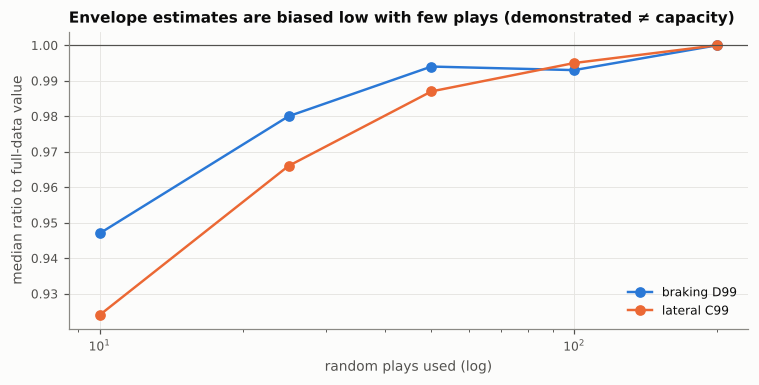

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(rel["k"], rel["D99_ratio_to_full"], marker="o", color=style.SERIES[0], label="braking D99")
ax.plot(rel["k"], rel["C99_ratio_to_full"], marker="o", color=style.SERIES[1], label="lateral C99")
ax.axhline(1, color=style.TEXT2, lw=.8); ax.set_xscale("log"); ax.set_xlabel("random plays used (log)"); ax.set_ylabel("median ratio to full-data value")
ax.set_title("Envelope estimates are biased low with few plays (demonstrated ≠ capacity)", loc="left", fontsize=10); ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "exposure_envelopes")

## A7 · Convergent check: combine braking vs game braking (same players)

In [11]:
cg = CM.join(base.filter(pl.col("variant")=="pos7").select("nfl_id","pos","n_plays","D99","C99"), on="nfl_id").filter(pl.col("n_plays")>=100)
rows=[]
for fam in ["agility","skill"]:
    d = cg.filter(pl.col("family")==fam)
    for a,b in [("D99_combine","D99"),("C99_combine","C99")]:
        r,lo,hi,n = boot_r(d[a], d[b])
        # within-position ranks
        d2 = d.with_columns((pl.col(a).rank().over("pos")/pl.len().over("pos")).alias("ra"), (pl.col(b).rank().over("pos")/pl.len().over("pos")).alias("rb"))
        rw,lw,hw,_ = boot_r(d2["ra"], d2["rb"])
        rows.append(dict(combine_family=fam, pair=f"{a} ↔ game {b}", n=n, pooled_rho=round(r,3), pooled_CI=f"[{lo:.2f}, {hi:.2f}]", within_position_rho=round(rw,3), within_CI=f"[{lw:.2f}, {hw:.2f}]"))
pl.DataFrame(rows)

combine_family,pair,n,pooled_rho,pooled_CI,within_position_rho,within_CI
str,str,i64,f64,str,f64,str
"""agility""","""D99_combine ↔ game D99""",134,0.409,"""[0.26, 0.54]""",0.042,"""[-0.15, 0.23]"""
"""agility""","""C99_combine ↔ game C99""",134,0.295,"""[0.12, 0.45]""",0.083,"""[-0.09, 0.25]"""
"""skill""","""D99_combine ↔ game D99""",307,0.552,"""[0.45, 0.64]""",0.119,"""[0.01, 0.23]"""
"""skill""","""C99_combine ↔ game C99""",307,0.75,"""[0.68, 0.80]""",0.14,"""[0.03, 0.25]"""


# Part B — Experiment 3: turning and lateral constraints
## B1 · Two independent lateral estimators: positions vs provided heading

In [12]:
FA.filter(pl.col("kind")=="a_n").group_by("variant").agg(pl.col("n").sum(), pl.col("corr_with_pos7").mean().round(3),
    (pl.col("frac_implausible")*pl.col("n")).sum().truediv(pl.col("n").sum()).mul(100).round(4).alias("pct_frames_a_n>15"),
    pl.col("p99_brake").mean().round(2).alias("mean_p99_a_n")).sort("variant")

variant,n,corr_with_pos7,pct_frames_a_n>15,mean_p99_a_n
str,i64,f64,f64,f64
"""an_5hz""",7268732,0.991,0.0001,5.42
"""an_dir""",15722689,0.957,0.0001,5.66
"""an_noise0.01""",15722692,0.985,0.0012,5.55
"""an_noise0.02""",15722692,0.945,0.0013,5.63
"""an_pos5""",15722692,0.977,0.0055,5.68
"""an_pos7""",15722692,1.0,0.0012,5.52
"""an_pos9""",15458787,0.994,0.0001,5.4


In [13]:
W2 = base.pivot(on="variant", index="nfl_id", values="C99").join(base.filter(pl.col("variant")=="pos7").select("nfl_id","n_plays"), on="nfl_id").filter(pl.col("n_plays")>=100)
rows=[]
for v in ["pos5","pos9","speed_sg7","noise0.02","5hz"]:
    r,lo,hi,n = boot_r(W2["pos7"], W2[v]); rows.append(dict(variant=v + (" (heading-based a_n)" if v=="speed_sg7" else ""), n=n, spearman_with_pos7=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]", median_ratio=round(float(np.nanmedian(W2[v]/W2["pos7"])),3)))
pl.DataFrame(rows)

variant,n,spearman_with_pos7,CI95,median_ratio
str,i64,f64,str,f64
"""pos5""",307,0.998,"""[1.00, 1.00]""",1.027
"""pos9""",307,0.999,"""[1.00, 1.00]""",0.979
"""speed_sg7 (heading-based a_n)""",307,0.997,"""[1.00, 1.00]""",1.029
"""noise0.02""",307,0.998,"""[1.00, 1.00]""",1.02
"""5hz""",307,0.999,"""[1.00, 1.00]""",0.974


## B2 · Speed–curvature relationship
For a constant lateral limit C, the curvature envelope is κ_max(v) = C / v². That is a slope of **−2** in log κ vs log v. A slope shallower than −2 means the achievable lateral acceleration *grows* with speed, or that tight turns at low speed are under-sampled. The slope is fitted to the 99th and 99.9th percentile of curvature per 0.5 yd/s speed bin, over 2–8 yd/s.

pos,envelope,slope_logk_logv,CI95
str,str,f64,str
"""WR""","""q990""",-1.95,"""[-2.00, -1.89]"""
"""WR""","""q999""",-2.07,"""[-2.10, -2.04]"""
"""TE""","""q990""",-2.02,"""[-2.10, -1.96]"""
"""TE""","""q999""",-2.1,"""[-2.15, -2.06]"""
"""OL""","""q990""",-2.05,"""[-2.24, -1.94]"""
"""OL""","""q999""",-2.11,"""[-2.23, -2.01]"""
"""DL""","""q990""",-2.04,"""[-2.21, -1.92]"""
"""DL""","""q999""",-2.07,"""[-2.17, -1.99]"""
"""DB""","""q990""",-2.1,"""[-2.14, -2.06]"""


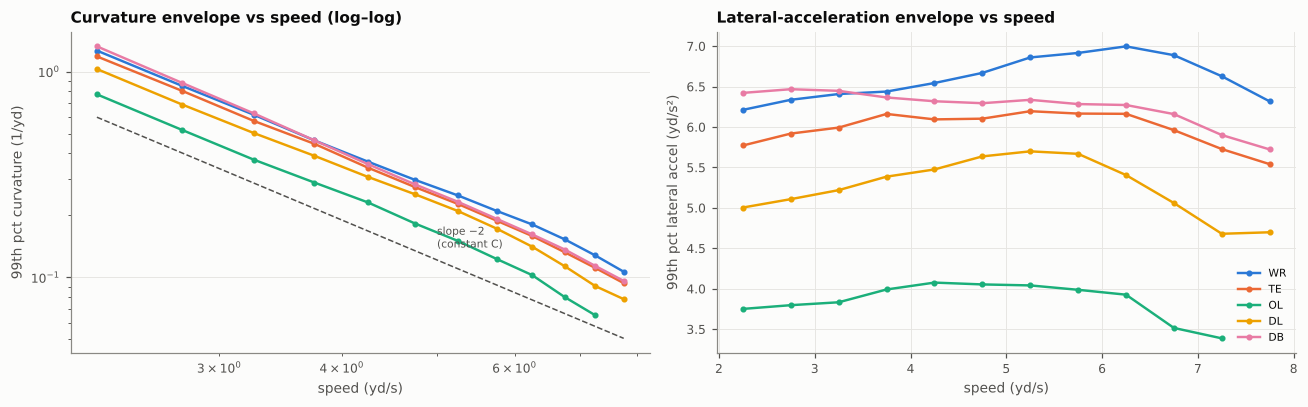

In [14]:
rows=[]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for p in POS:
    q = SB.filter((pl.col("pos")==p) & pl.col("v_bin").is_between(2, 7.5) & (pl.col("n")>2000)).sort("v_bin")
    v = q["v_bin"].to_numpy() + 0.25
    for qq,ax in (("kappa7_q990",axes[0]),("an_pos7_q990",axes[1])):
        ax.plot(v, q[qq], marker="o", ms=3, color=PCOL[p], label=p)
    for qq in ("kappa7_q990","kappa7_q999"):
        y = np.log(q[qq].to_numpy()); X = np.log(v)
        b, a = np.polyfit(X, y, 1)
        bs=[];
        for _ in range(1000):
            i=rng.integers(0,len(X),len(X)); bs.append(np.polyfit(X[i],y[i],1)[0])
        rows.append(dict(pos=p, envelope=qq.replace("kappa7_",""), slope_logk_logv=round(b,2), CI95=f"[{np.percentile(bs,2.5):.2f}, {np.percentile(bs,97.5):.2f}]"))
axes[0].set_yscale("log"); axes[0].set_xscale("log"); axes[0].set_xlabel("speed (yd/s)"); axes[0].set_ylabel("99th pct curvature (1/yd)"); axes[0].set_title("Curvature envelope vs speed (log–log)", loc="left", fontsize=10)
vv=np.linspace(2.25,7.75,20); axes[0].plot(vv, 0.6*(vv/2.25)**-2, color=style.TEXT2, ls="--", lw=1); axes[0].text(5,0.6*(5/2.25)**-2*1.15,"slope −2\n(constant C)",fontsize=7,color=style.TEXT2)
axes[1].set_xlabel("speed (yd/s)"); axes[1].set_ylabel("99th pct lateral accel (yd/s²)"); axes[1].set_title("Lateral-acceleration envelope vs speed", loc="left", fontsize=10); axes[1].legend(fontsize=7)
fig.tight_layout(); save(fig, "speed_curvature")
pl.DataFrame(rows)

- The bootstrap here resamples speed bins, a crude summary.
- Bins pool many players, so the envelope is a *population* envelope, not an individual limit.

## B3 · Context dependence (same players, different movement contexts)

In [15]:
ctx = PM.filter((pl.col("scope")=="all_") & (pl.col("variant")=="pos7") & (pl.col("context")!="all_plays") & (pl.col("n_plays")>=30))
ctx.group_by("pos","context").agg(pl.len().alias("players"), pl.col("n_plays").median().alias("median_plays"), pl.col("C99").median().round(2), pl.col("D99").median().round(2),
    pl.col("kappa99_v4_6").median().round(3)).sort("pos","context")

pos,context,players,median_plays,C99,D99,kappa99_v4_6
str,str,u32,f64,f32,f32,f32
"""DB""","""play_type=pass""",80,400.0,6.36,5.59,0.312
"""DB""","""play_type=run""",75,270.0,5.7,5.16,0.278
"""DL""","""play_type=pass""",85,221.0,5.23,4.2,0.266
"""DL""","""play_type=run""",88,175.5,4.7,4.27,0.241
"""OL""","""play_type=pass""",75,629.0,3.92,3.24,0.214
"""OL""","""play_type=run""",73,419.0,3.76,3.36,0.189
"""TE""","""play_type=pass""",26,226.0,6.12,5.26,0.292
"""TE""","""play_type=unknown""",7,47.0,5.58,4.5,0.282
"""TE""","""route_group=breaking""",23,158.0,6.23,5.34,0.302


In [16]:
rows=[]
for p in POS:
    for a,b,m in [("play_type=pass","play_type=run","C99"),("play_type=pass","play_type=run","D99"),("route_group=breaking","route_group=vertical","C99"),("route_group=breaking","route_group=vertical","D99")]:
        w = ctx.filter((pl.col("pos")==p)&pl.col("context").is_in([a,b])).pivot(on="context", index="nfl_id", values=m)
        if a not in w.columns or b not in w.columns: continue
        w = w.drop_nulls([a,b])
        if w.height < 8: continue
        d = (w[a]-w[b]).to_numpy(); bs=[np.median(d[rng.integers(0,len(d),len(d))]) for _ in range(2000)]
        r,lo,hi,n = boot_r(w[a], w[b])
        rows.append(dict(pos=p, measure=m, contrast=f"{a.split('=')[1]} − {b.split('=')[1]}", n=w.height, median_diff=round(float(np.median(d)),2),
                         CI95=f"[{np.percentile(bs,2.5):.2f}, {np.percentile(bs,97.5):.2f}]", cross_context_rank_rho=round(r,3)))
pl.DataFrame(rows)

pos,measure,contrast,n,median_diff,CI95,cross_context_rank_rho
str,str,str,i64,f64,str,f64
"""WR""","""C99""","""breaking − vertical""",61,0.97,"""[0.82, 1.07]""",0.474
"""WR""","""D99""","""breaking − vertical""",61,0.48,"""[0.34, 0.59]""",0.41
"""TE""","""C99""","""breaking − vertical""",11,0.68,"""[0.43, 0.92]""",0.627
"""TE""","""D99""","""breaking − vertical""",11,0.22,"""[-0.40, 0.53]""",0.036
"""OL""","""C99""","""pass − run""",71,0.13,"""[0.03, 0.27]""",0.131
"""OL""","""D99""","""pass − run""",71,-0.2,"""[-0.29, -0.08]""",0.133
"""DL""","""C99""","""pass − run""",84,0.54,"""[0.38, 0.63]""",0.741
"""DL""","""D99""","""pass − run""",84,-0.17,"""[-0.22, -0.11]""",0.75
"""DB""","""C99""","""pass − run""",74,0.65,"""[0.54, 0.79]""",0.189


- **Median within-player differences** show whether the measured "limit" depends on context. If it does, it is not a fixed capacity.
- **Cross-context rank correlation** shows whether players keep their order across contexts.

## B4 · Stability of lateral envelopes

In [17]:
rows=[]
for m in ["C99","kappa99_v2_4","kappa99_v4_6","kappa99_v6_8","Cmax"]:
    for v in ["pos7","speed_sg7","5hz"]:
        rows += split_half(m, v)
REL_L = pl.DataFrame(rows); REL_L.pivot(on="variant", index="measure", values="spearman_brown")

measure,pos7,speed_sg7,5hz
str,f64,f64,f64
"""C99""",0.968,0.969,0.969
"""kappa99_v2_4""",0.941,0.941,0.941
"""kappa99_v4_6""",0.901,0.901,0.901
"""kappa99_v6_8""",0.92,0.92,0.92
"""Cmax""",0.882,0.894,0.892


In [18]:
pl.DataFrame(sum([split_half(m, "pos7", by_pos=True) for m in ["C99","D99"]], [])).filter(pl.col("group")!="ALL")

measure,variant,context,group,n,split_half_rho,CI95,spearman_brown
str,str,str,str,i64,f64,str,f64
"""C99""","""pos7""","""all_plays""","""WR""",63,0.727,"""[0.55, 0.85]""",0.842
"""C99""","""pos7""","""all_plays""","""TE""",22,0.756,"""[0.44, 0.89]""",0.861
"""C99""","""pos7""","""all_plays""","""OL""",70,0.308,"""[0.07, 0.53]""",0.471
"""C99""","""pos7""","""all_plays""","""DL""",78,0.788,"""[0.67, 0.86]""",0.881
"""C99""","""pos7""","""all_plays""","""DB""",74,0.431,"""[0.22, 0.63]""",0.602
"""D99""","""pos7""","""all_plays""","""WR""",63,0.467,"""[0.21, 0.67]""",0.637
"""D99""","""pos7""","""all_plays""","""TE""",22,0.567,"""[0.17, 0.83]""",0.724
"""D99""","""pos7""","""all_plays""","""OL""",70,0.505,"""[0.26, 0.69]""",0.671
"""D99""","""pos7""","""all_plays""","""DL""",78,0.867,"""[0.79, 0.91]""",0.929


# Part C — Experiment 4: CCMT execution cost on real combine drills
## C1 · Coverage, timing validity and plausibility

In [19]:
print(A.group_by("drill","status").agg(pl.col("event_id").n_unique().alias("attempts")).sort("drill","status"))
B0 = A.filter((pl.col("status")=="ok")&(pl.col("window")==7)&(pl.col("onset")=="raw")&pl.col("stops_modelled"))
base_lim = B0.filter(pl.col("limits")=="grid_D6.5_C7.0")
print("valid attempts (base variant):", base_lim.height, "| players:", base_lim["nfl_id"].n_unique())
tv=[]
for dr in ["THREE_CONE_DRILL","SHORT_SHUTTLE"]:
    d = base_lim.filter(pl.col("drill")==dr).sort("T_track").group_by("nfl_id").first()
    r,lo,hi,n = boot_r(d["T_track"], d["official"], f=lambda a,b: pearsonr(a,b).statistic)
    tv.append(dict(drill=dr, players=n, r_track_vs_official=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]", median_track_minus_official=round(float(np.nanmedian(d["T_track"]-d["official"])),3),
                   n_stops_mean=round(d["n_stops"].mean(),2), L_path_median=round(d["L_path"].median(),2)))
pl.DataFrame(tv)

┌──────────────────┬────────────────────┬──────────┐
│ drill            ┆ status             ┆ attempts │
│ ---              ┆ ---                ┆ ---      │
│ str              ┆ str                ┆ u32      │
╞══════════════════╪════════════════════╪══════════╡
│ SHORT_SHUTTLE    ┆ no 40 tracking     ┆ 24       │
│ SHORT_SHUTTLE    ┆ no finish crossing ┆ 40       │
│ SHORT_SHUTTLE    ┆ no movement        ┆ 3        │
│ SHORT_SHUTTLE    ┆ ok                 ┆ 158      │
│ THREE_CONE_DRILL ┆ no 40 tracking     ┆ 22       │
│ THREE_CONE_DRILL ┆ no finish crossing ┆ 8        │
│ THREE_CONE_DRILL ┆ no movement        ┆ 1        │
│ THREE_CONE_DRILL ┆ ok                 ┆ 172      │
└──────────────────┴────────────────────┴──────────┘
valid attempts (base variant): 330 | players: 176


drill,players,r_track_vs_official,CI95,median_track_minus_official,n_stops_mean,L_path_median
str,i64,f64,str,f64,f64,f64
"""THREE_CONE_DRILL""",128,0.649,"""[0.36, 0.89]""",0.237,2.62,22.06
"""SHORT_SHUTTLE""",117,0.403,"""[0.27, 0.69]""",0.426,1.99,14.8


**Timing validity is the first limitation.**
- Tracking-derived gate times correlate only moderately with official times, and weakly for the shuttle. Recordings often begin after the athlete is already moving, and official timing differs in protocol.
- Body-sensor paths are shorter than the nominal drills (the shuttle path is about 15 yd vs 20 yd nominal), because athletes reach with the hand to touch the lines.

In [20]:
pl_ = B0.group_by("drill","limits").agg(pl.len().alias("attempts"), pl.col("E").median().round(3).alias("median_E"), (pl.col("E")<0).mean().round(3).alias("frac_E_negative")).sort("drill","limits")
pl_

drill,limits,attempts,median_E,frac_E_negative
str,str,u32,f64,f64
"""SHORT_SHUTTLE""","""grid_D5.0_C5.0""",158,-0.194,0.778
"""SHORT_SHUTTLE""","""grid_D5.0_C7.0""",158,-0.145,0.703
"""SHORT_SHUTTLE""","""grid_D5.0_C9.0""",158,-0.108,0.684
"""SHORT_SHUTTLE""","""grid_D6.5_C5.0""",158,0.033,0.449
"""SHORT_SHUTTLE""","""grid_D6.5_C7.0""",158,0.094,0.278
"""SHORT_SHUTTLE""","""grid_D6.5_C9.0""",158,0.129,0.215
"""SHORT_SHUTTLE""","""grid_D8.0_C5.0""",158,0.167,0.228
"""SHORT_SHUTTLE""","""grid_D8.0_C7.0""",158,0.248,0.108
"""SHORT_SHUTTLE""","""grid_D8.0_C9.0""",158,0.281,0.076


**A negative execution cost is physically implausible:** the athlete ran faster than the model says is possible for them. It means the assumed braking/lateral limits (or the forced zero-speed stops) are too conservative for that athlete.
- The share of negative values is a direct, outcome-free check of the limit assumptions.
- Braking (D) and lateral (C) limits **cannot be estimated from the drills themselves without circularity** (Phase 1.6). The `position_game` and `player_game` rows use game-derived envelopes (Part A/B) instead.

## C2 · Relationship with 40-yd time, COD deficit and drill time (best valid attempt per player)

In [21]:
def best_attempt(df): return df.sort("T_track").group_by(["nfl_id","drill"]).first()
rows=[]
for lim in ["grid_D6.5_C7.0","grid_D8.0_C9.0","position_game","player_game"]:
    d = best_attempt(B0.filter(pl.col("limits")==lim))
    for dr in ["THREE_CONE_DRILL","SHORT_SHUTTLE"]:
        q = d.filter(pl.col("drill")==dr)
        for other in ["forty","S0","codd","codd_pct","T_track","official"]:
            r,lo,hi,n = boot_r(q["E"], q[other]); rows.append(dict(limits=lim, drill=dr, with_=other, n=n, rho=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]"))
REL_E = pl.DataFrame(rows)
REL_E.pivot(on="with_", index=["limits","drill"], values="rho")

limits,drill,forty,S0,codd,codd_pct,T_track,official
str,str,f64,f64,f64,f64,f64,f64
"""grid_D6.5_C7.0""","""THREE_CONE_DRILL""",-0.179,0.133,0.566,0.648,0.101,-0.143
"""grid_D6.5_C7.0""","""SHORT_SHUTTLE""",0.119,-0.189,0.785,0.742,0.49,0.138
"""grid_D8.0_C9.0""","""THREE_CONE_DRILL""",-0.227,0.166,0.611,0.682,0.122,-0.151
"""grid_D8.0_C9.0""","""SHORT_SHUTTLE""",0.053,-0.133,0.813,0.803,0.472,0.081
"""position_game""","""THREE_CONE_DRILL""",-0.772,0.734,0.16,0.823,-0.458,-0.74
"""position_game""","""SHORT_SHUTTLE""",-0.617,0.545,0.4,0.79,-0.092,-0.52
"""player_game""","""THREE_CONE_DRILL""",-0.809,0.768,0.167,0.826,-0.496,-0.777
"""player_game""","""SHORT_SHUTTLE""",-0.627,0.549,0.303,0.719,-0.151,-0.579


In [22]:
d = best_attempt(B0.filter(pl.col("limits")=="grid_D6.5_C7.0"))
rows=[]
for dr in ["THREE_CONE_DRILL","SHORT_SHUTTLE"]:
    q=d.filter(pl.col("drill")==dr)
    for m in ["codd","codd_pct","T_track"]:
        r,lo,hi,n=boot_r(q[m],q["forty"]); rows.append(dict(drill=dr, measure=m, n=n, rho_with_forty=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]"))
pl.DataFrame(rows)

drill,measure,n,rho_with_forty,CI95
str,str,i64,f64,str
"""THREE_CONE_DRILL""","""codd""",137,0.043,"""[-0.12, 0.19]"""
"""THREE_CONE_DRILL""","""codd_pct""",137,-0.759,"""[-0.82, -0.68]"""
"""THREE_CONE_DRILL""","""T_track""",137,0.624,"""[0.50, 0.73]"""
"""SHORT_SHUTTLE""","""codd""",125,0.106,"""[-0.07, 0.28]"""
"""SHORT_SHUTTLE""","""codd_pct""",125,-0.419,"""[-0.57, -0.25]"""
"""SHORT_SHUTTLE""","""T_track""",125,0.532,"""[0.39, 0.66]"""


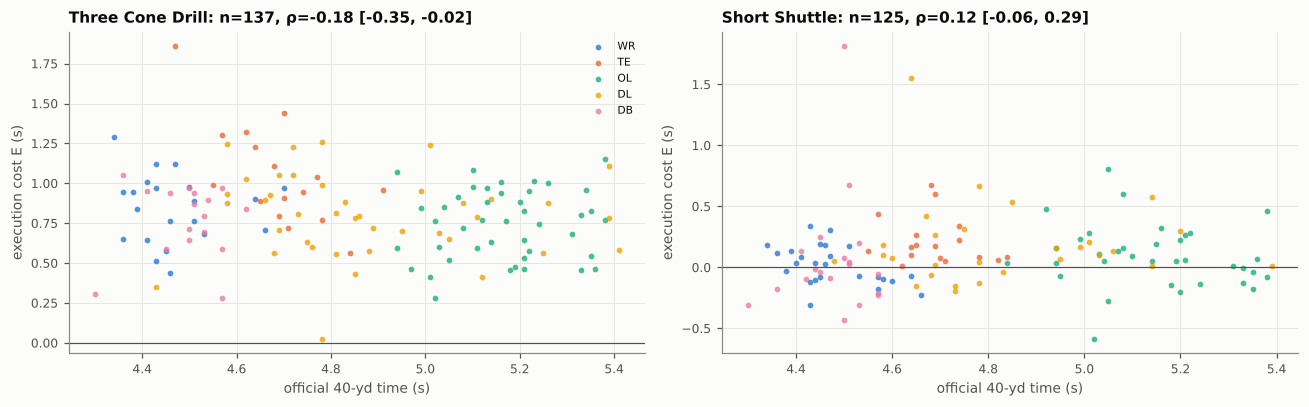

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, dr in zip(axes, ["THREE_CONE_DRILL","SHORT_SHUTTLE"]):
    q = d.filter(pl.col("drill")==dr)
    for p in POS:
        qq=q.filter(pl.col("pos")==p); ax.scatter(qq["forty"], qq["E"], s=14, color=PCOL[p], alpha=.8, linewidths=0, label=p)
    r,lo,hi,n=boot_r(q["forty"],q["E"])
    ax.axhline(0,color=style.TEXT2,lw=.8); ax.set_xlabel("official 40-yd time (s)"); ax.set_ylabel("execution cost E (s)")
    ax.set_title(f"{dr.replace('_',' ').title()}: n={n}, ρ={r:.2f} [{lo:.2f}, {hi:.2f}]", loc="left", fontsize=10)
axes[0].legend(fontsize=7)
fig.tight_layout(); save(fig, "execution_vs_forty")

## C3 · Drill differences: is execution cost consistent across the two drills?

In [24]:
w = d.pivot(on="drill", index=["nfl_id","pos"], values="E").drop_nulls()
r,lo,hi,n = boot_r(w["THREE_CONE_DRILL"], w["SHORT_SHUTTLE"])
w2 = d.pivot(on="drill", index=["nfl_id","pos"], values="codd").drop_nulls(); r2,lo2,hi2,n2 = boot_r(w2["THREE_CONE_DRILL"], w2["SHORT_SHUTTLE"])
w3 = d.pivot(on="drill", index=["nfl_id","pos"], values="official").drop_nulls(); r3,lo3,hi3,n3 = boot_r(w3["THREE_CONE_DRILL"], w3["SHORT_SHUTTLE"])
pl.DataFrame([dict(measure="execution cost E", n=n, rho_3cone_vs_shuttle=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]"),
              dict(measure="COD deficit (tracking)", n=n2, rho_3cone_vs_shuttle=round(r2,3), CI95=f"[{lo2:.2f}, {hi2:.2f}]"),
              dict(measure="official drill time", n=n3, rho_3cone_vs_shuttle=round(r3,3), CI95=f"[{lo3:.2f}, {hi3:.2f}]")])

measure,n,rho_3cone_vs_shuttle,CI95
str,i64,f64,str
"""execution cost E""",86,0.388,"""[0.17, 0.57]"""
"""COD deficit (tracking)""",86,0.292,"""[0.08, 0.51]"""
"""official drill time""",80,0.901,"""[0.85, 0.93]"""


## C4 · Sensitivity: are rankings robust to reasonable methodological changes?

In [25]:
ok = A.filter(pl.col("status")=="ok")
ref = ok.filter((pl.col("window")==7)&(pl.col("onset")=="raw")&pl.col("stops_modelled")&(pl.col("limits")=="grid_D6.5_C7.0")).select("event_id", pl.col("E").alias("E_ref"), "drill")
variants = {"window 5": (pl.col("window")==5)&(pl.col("onset")=="raw")&pl.col("stops_modelled")&(pl.col("limits")=="grid_D6.5_C7.0"),
            "window 9": (pl.col("window")==9)&(pl.col("onset")=="raw")&pl.col("stops_modelled")&(pl.col("limits")=="grid_D6.5_C7.0"),
            "onset extrapolated": (pl.col("window")==7)&(pl.col("onset")=="extrapolated")&pl.col("stops_modelled")&(pl.col("limits")=="grid_D6.5_C7.0"),
            "no stop constraints": (pl.col("window")==7)&(pl.col("onset")=="raw")&~pl.col("stops_modelled")&(pl.col("limits")=="grid_D6.5_C7.0")}
for lim in ["grid_D5.0_C5.0","grid_D8.0_C9.0","grid_D5.0_C9.0","grid_D8.0_C5.0","position_game","player_game","no_lateral_D6.5"]:
    variants[f"limits {lim}"] = (pl.col("window")==7)&(pl.col("onset")=="raw")&pl.col("stops_modelled")&(pl.col("limits")==lim)
rows=[]
for name, cond in variants.items():
    j = ok.filter(cond).select("event_id", "E").join(ref, on="event_id")
    for dr in ["THREE_CONE_DRILL","SHORT_SHUTTLE"]:
        q=j.filter(pl.col("drill")==dr); r,lo,hi,n=boot_r(q["E_ref"],q["E"])
        rows.append(dict(variant=name, drill=dr, n=n, rank_rho_vs_reference=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]",
                         median_shift_s=round(float(np.nanmedian(q["E"]-q["E_ref"])),3)))
SENS = pl.DataFrame(rows); SENS

variant,drill,n,rank_rho_vs_reference,CI95,median_shift_s
str,str,i64,f64,str,f64
"""window 5""","""THREE_CONE_DRILL""",172,0.968,"""[0.95, 0.98]""",-0.029
"""window 5""","""SHORT_SHUTTLE""",158,0.984,"""[0.97, 0.99]""",-0.005
"""window 9""","""THREE_CONE_DRILL""",172,0.978,"""[0.96, 0.99]""",0.008
"""window 9""","""SHORT_SHUTTLE""",158,0.99,"""[0.98, 1.00]""",0.001
"""onset extrapolated""","""THREE_CONE_DRILL""",172,0.895,"""[0.84, 0.93]""",0.193
"""onset extrapolated""","""SHORT_SHUTTLE""",158,0.886,"""[0.81, 0.94]""",0.171
"""no stop constraints""","""THREE_CONE_DRILL""",172,0.847,"""[0.78, 0.89]""",0.326
"""no stop constraints""","""SHORT_SHUTTLE""",158,0.892,"""[0.81, 0.95]""",0.215
"""limits grid_D5.0_C5.0""","""THREE_CONE_DRILL""",172,0.954,"""[0.93, 0.97]""",-0.703


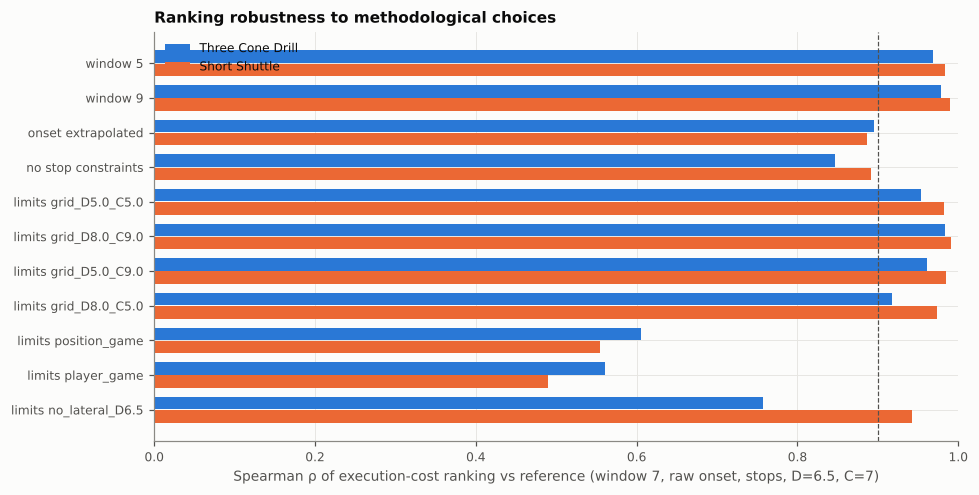

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.6))
names = list(variants)
for i, dr in enumerate(["THREE_CONE_DRILL","SHORT_SHUTTLE"]):
    v = [SENS.filter((pl.col("variant")==nm)&(pl.col("drill")==dr))["rank_rho_vs_reference"][0] for nm in names]
    ax.barh(np.arange(len(names))+(i-0.5)*0.38, v, height=0.36, color=style.SERIES[i], label=dr.replace("_"," ").title())
ax.set_yticks(range(len(names)), names, fontsize=8); ax.invert_yaxis(); ax.set_xlim(0,1); ax.axvline(0.9,color=style.TEXT2,ls="--",lw=.8)
ax.set_xlabel("Spearman ρ of execution-cost ranking vs reference (window 7, raw onset, stops, D=6.5, C=7)"); ax.legend(fontsize=8)
ax.set_title("Ranking robustness to methodological choices", loc="left", fontsize=10)
fig.tight_layout(); save(fig, "execution_sensitivity")

## C5 · Within-player reliability: only where two valid attempts exist

In [27]:
two = B0.filter(pl.col("limits")=="grid_D6.5_C7.0").group_by("nfl_id","drill").agg(pl.len().alias("k"), pl.col("E").sort_by("attempt"), pl.col("codd").sort_by("attempt"), pl.col("T_track").sort_by("attempt")).filter(pl.col("k")>=2)
rows=[]
for dr in ["THREE_CONE_DRILL","SHORT_SHUTTLE"]:
    q=two.filter(pl.col("drill")==dr)
    for m in ["E","codd","T_track"]:
        a=np.array([v[0] for v in q[m]]); b=np.array([v[1] for v in q[m]])
        r,lo,hi,n=boot_r(a,b,f=lambda u,v: pearsonr(u,v).statistic)
        rows.append(dict(drill=dr, measure=m, players_with_2_valid_attempts=n, test_retest_r=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]",
                         typical_error_s=round(float(np.std(b-a,ddof=1)/np.sqrt(2)),3) if n>2 else np.nan))
pl.DataFrame(rows)

drill,measure,players_with_2_valid_attempts,test_retest_r,CI95,typical_error_s
str,str,i64,f64,str,f64
"""THREE_CONE_DRILL""","""E""",32,0.584,"""[0.39, 0.78]""",0.305
"""THREE_CONE_DRILL""","""codd""",32,0.39,"""[0.12, 0.68]""",0.486
"""THREE_CONE_DRILL""","""T_track""",32,0.404,"""[0.16, 0.72]""",0.577
"""SHORT_SHUTTLE""","""E""",28,0.195,"""[0.04, 0.52]""",0.39
"""SHORT_SHUTTLE""","""codd""",28,-0.42,"""[-0.68, 0.31]""",0.678
"""SHORT_SHUTTLE""","""T_track""",28,-0.607,"""[-0.88, 0.25]""",0.948


Players with only one valid attempt are **not** used for any repeatability statement. Reliability here is within-session (same combine day) and based on small n, so the intervals are wide.

# Summary
See `research_notes/braking_estimation_validation.md`, `lateral_constraint_validation.md` and `combine_execution_cost.md`.